# Лабораторная 4. Кошки и собаки

Maksim Kostromitin  
Group: J4132

Сравниваю свёрточную сеть с тремя свёртками, VGG16 и ResNet18. Затем проверяю отдельную фотографию и конкурсный ансамбль.

Запуск из папки `lab4`; зависимости указаны в `requirements.txt`. По умолчанию используются сохранённые результаты. `RETRAIN = True` повторяет обучение основной части, `RUN_TEST = True` пересчитывает ответы по фотографиям тестовой выборки.


In [1]:
from pathlib import Path
from contextlib import nullcontext
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import models, transforms
from torchvision.models.vgg import cfgs, make_layers

import hw4
import contest

results, manifests = hw4.prepare()
RETRAIN = False
RUN_TEST = False
required_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
required_work = hw4.CACHE / "required-training"

## Данные

Кошка — класс 0, собака — класс 1. Использую разбиение курса: обучающую выборку для изменения весов, проверочную для выбора эпохи, тестовую для итоговой оценки. Столбец `use` исключает найденные точные дубликаты между выборками.


In [2]:
manifest = pd.read_csv(manifests / "course_all.csv")
manifest.loc[manifest.use].groupby("split").size().reindex(
    ["train", "val", "test"]
).to_frame("Фотографии").rename(index={"train": "Обучающая выборка", "val": "Проверочная выборка", "test": "Тестовая выборка"}).rename_axis("Выборка")

,Фотографии
Выборка,
Обучающая выборка,19997
Проверочная выборка,2490
Тестовая выборка,2500


In [3]:
def accuracy(labels, probabilities):
    correct = (np.asarray(probabilities) >= 0.5) == np.asarray(labels)
    return pd.Series(
        {
            "Верно": int(correct.sum()),
            "Всего": len(correct),
            "Accuracy, %": round(100 * correct.mean(), 2),
        }
    )

class CoursePhotos(Dataset):
    def __init__(self, root, rows, transform):
        self.root, self.transform = root, transform
        self.paths = rows.relative_path.tolist()
        self.labels = rows.label.tolist()

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.root / self.paths[i]) as photo:
            image = ImageOps.exif_transpose(photo).convert("RGB")
            return self.transform(image), self.labels[i]

def course_splits(root, transform):
    rows = pd.read_csv(manifests / "course_all.csv")
    return [
        CoursePhotos(root, rows.loc[rows.use & (rows.split == split)], transform)
        for split in ("train", "val")
    ]


def required_loader(dataset, batch, shuffle=False):
    generator = torch.Generator().manual_seed(42)
    return DataLoader(dataset, batch_size=batch, shuffle=shuffle, generator=generator)

## 1. Свёрточная сеть с тремя свёртками

Три блока: свёртка 3 × 3, обнуление отрицательных значений и уменьшение карты признаков по максимумам. После них идут 64 нейрона, случайное отключение нейронов с вероятностью 0,5 при обучении и один выход. Модель возвращает логит; сигмоида уже входит в функцию потерь `binary_cross_entropy_with_logits`.


In [4]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        layers = []
        for inputs, outputs in [(3, 16), (16, 32), (32, 64)]:
            layers.extend(
                [nn.Conv2d(inputs, outputs, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
            )
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 18 * 18, 64),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.head(self.features(x)).flatten()

In [5]:
simple_transform = transforms.Compose([
    transforms.Resize((150, 150)), transforms.ToTensor()
])
transfer_transform = models.VGG16_Weights.IMAGENET1K_V1.transforms()


def required_precision():
    if required_device.type == "cuda":
        return torch.autocast("cuda", dtype=torch.float16)
    return nullcontext()

### Обучение

На обучающей выборке обновляю веса, на проверочной считаю потери и долю верных ответов без градиентов. Сохраняю эпоху с наибольшей точностью на проверочной выборке; при равенстве выбираю меньшие потери.


In [6]:
def update_required_weights(model, loss, optimizer, scaler):
    optimizer.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=5)
    scaler.step(optimizer)
    scaler.update()

def required_epoch(model, loader, optimizer=None, scaler=None):
    model.train(optimizer is not None)
    loss_sum, correct = 0.0, 0
    for images, labels in loader:
        x, y = images.to(required_device), labels.to(required_device).float()
        with torch.set_grad_enabled(optimizer is not None), required_precision():
            logits = model(x).flatten().float()
            loss = nn.functional.binary_cross_entropy_with_logits(logits, y)
        if optimizer is not None:
            update_required_weights(model, loss, optimizer, scaler)
        loss_sum += loss.item() * len(y)
        correct += ((logits.detach() >= 0) == y.bool()).sum().item()
    return loss_sum / len(loader.dataset), correct / len(loader.dataset)

In [7]:
def fit_required(model, train, val, optimizer, epochs, name):
    required_work.mkdir(parents=True, exist_ok=True)
    scaler = torch.amp.GradScaler("cuda", enabled=required_device.type == "cuda")
    records, best = [], (-1.0, -float("inf"))
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = required_epoch(model, train, optimizer, scaler)
        val_loss, val_acc = required_epoch(model, val)
        records.append((name, epoch, train_loss, train_acc, val_loss, val_acc))
        if (val_acc, -val_loss) > best:
            best = (val_acc, -val_loss)
            torch.save(
                {"state_dict": model.state_dict(), "epoch": epoch},
                required_work / f"{name}.pt",
            )
    columns = [
        "model",
        "epoch",
        "train_loss",
        "train_accuracy",
        "val_loss",
        "val_accuracy",
    ]
    return pd.DataFrame(records, columns=columns)

if RETRAIN:
    torch.manual_seed(42)
    photos_root = hw4.extract_photos()
    train_photos, val_photos = course_splits(photos_root, simple_transform)
    cnn = BaselineCNN().to(required_device)
    cnn_optimizer = torch.optim.Adam(cnn.parameters(), lr=0.001)
    required_histories = [
        fit_required(
            cnn,
            required_loader(train_photos, 64, True),
            required_loader(val_photos, 64),
            cnn_optimizer,
            8,
            "cnn_baseline",
        )
    ]

## 2. Перенос обучения

У VGG16 и ResNet18 замораживаю свёрточную часть с весами ImageNet и обучаю новый классификатор. Фото приводятся к 224 × 224 и нормируются по ImageNet. Веса основ и обученных классификаторов хранятся в `models/required.zip`.

In [8]:
def required_backbone(arch):
    if arch == "vgg16":
        features = make_layers(cfgs["D"], batch_norm=False)
        return nn.Sequential(features, nn.AdaptiveAvgPool2d((7, 7)), nn.Flatten())
    base = models.resnet18(weights=None)
    base.fc = nn.Identity()
    return base


def required_head(arch):
    if arch == "vgg16":
        return nn.Sequential(
            nn.Linear(512 * 7 * 7, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, 1)
        )
    return nn.Linear(512, 1)

def required_parts(arch):
    runs = hw4.open_models("required") / "runs"
    fitted = torch.load(
        runs / f"{arch}_transfer.pt", map_location="cpu", weights_only=True
    )
    backbone_file = runs / fitted["transfer"]["backbone_checkpoint"]
    pretrained = torch.load(backbone_file, map_location="cpu", weights_only=True)
    backbone = required_backbone(arch)
    backbone.load_state_dict(pretrained["state_dict"])
    backbone.requires_grad_(False).eval()
    return backbone, fitted

Признаки извлекаю один раз и сохраняю на диск: для VGG16 они занимают около 2,3 ГБ. Затем обучается только классификатор.

In [9]:
@torch.no_grad()
def extract_required_features(backbone, dataset, width, file):
    count = len(dataset)
    features = torch.from_file(str(file), shared=True, size=count * width).view(
        count, width
    )
    offset = 0
    for images, labels in required_loader(dataset, 32):
        with required_precision():
            batch = backbone(images.to(required_device)).float().cpu()
        features[offset : offset + len(labels)].copy_(batch)
        offset += len(labels)
    return TensorDataset(features, torch.tensor(dataset.labels))

def train_required_head(arch, lr, batch_size):
    backbone, _ = required_parts(arch)
    backbone.to(required_device)
    train, val = course_splits(photos_root, transfer_transform)
    width = 512 * 7 * 7 if arch == "vgg16" else 512
    with TemporaryDirectory(dir=required_work) as tmp:
        train_features = extract_required_features(
            backbone, train, width, Path(tmp) / "train.bin"
        )
        val_features = extract_required_features(
            backbone, val, width, Path(tmp) / "val.bin"
        )
        torch.manual_seed(42)
        head = required_head(arch).to(required_device)
        optimizer = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=1e-4)
        run = fit_required(
            head,
            required_loader(train_features, batch_size, True),
            required_loader(val_features, batch_size),
            optimizer,
            12,
            f"{arch}_transfer",
        )
        del train_features, val_features
    return run

In [10]:
if RETRAIN:
    required_histories.append(train_required_head("vgg16", lr=0.0003, batch_size=128))
    required_histories.append(train_required_head("resnet18", lr=0.001, batch_size=256))
    history = pd.concat(required_histories, ignore_index=True)
    history.to_csv(required_work / "history.csv", index=False)
else:
    history = pd.read_csv(results / "required_history.csv")

### Кривые обучения

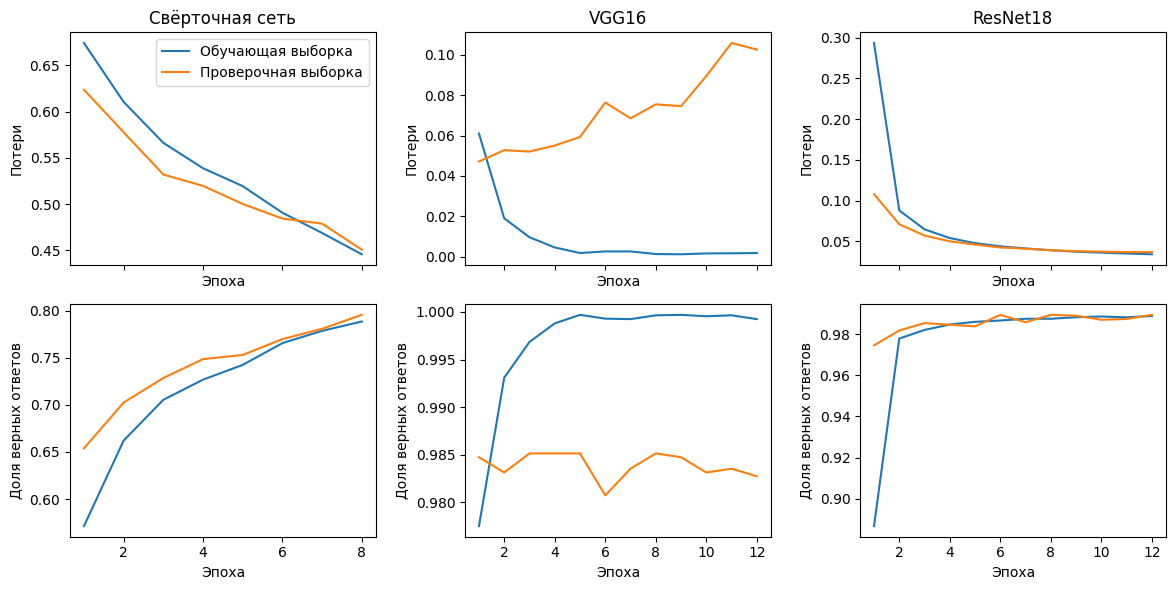

In [11]:
model_labels = {
    "cnn_baseline": "Свёрточная сеть",
    "vgg16_transfer": "VGG16",
    "resnet18_transfer": "ResNet18",
}
metric_labels = {"loss": "Потери", "accuracy": "Доля верных ответов"}

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex="col")
for column, (name, rows) in enumerate(history.groupby("model", sort=False)):
    for axis, metric in zip(axes[:, column], ["loss", "accuracy"]):
        axis.plot(rows.epoch, rows[f"train_{metric}"], label="Обучающая выборка")
        axis.plot(rows.epoch, rows[f"val_{metric}"], label="Проверочная выборка")
        axis.set(xlabel="Эпоха", ylabel=metric_labels[metric])
    axes[0, column].set_title(model_labels[name])
axes[0, 0].legend()
fig.tight_layout()
plt.show()

У VGG16 после первых эпох потери на обучающей выборке снижаются, а на проверочной растут: модель переобучается. Для тестовой оценки берутся веса лучшей эпохи по проверочной выборке.

### Результаты на тестовой выборке

При повторном обучении таблица считается по новым весам. При обычном запуске читаются сохранённые ответы на те же 2 500 фотографий.


In [12]:
def load_required_model(name):
    runs = hw4.open_models("required") / "runs"
    if name == "cnn_baseline":
        model = BaselineCNN()
    else:
        arch = name.removesuffix("_transfer")
        backbone, _ = required_parts(arch)
        model = nn.Sequential(backbone, required_head(arch))

    folder = required_work if RETRAIN else runs
    checkpoint = torch.load(folder / f"{name}.pt", map_location="cpu", weights_only=True)
    target = model if name == "cnn_baseline" else model[1]
    target.load_state_dict(checkpoint["state_dict"])
    return model.to(required_device).eval()


@torch.inference_mode()
def required_probabilities(model, dataset):
    parts = []
    for images, _ in required_loader(dataset, 32):
        logits = model(images.to(required_device)).flatten()
        parts.append(logits.sigmoid().cpu().numpy())
    return np.concatenate(parts)

In [13]:
names = ["cnn_baseline", "vgg16_transfer", "resnet18_transfer"]
if RETRAIN or RUN_TEST:
    root = hw4.extract_photos(split="test")
    rows = manifest.loc[manifest.split == "test"].sort_values("relative_path")
    required = rows[["relative_path", "label"]].rename(columns={"relative_path": "path"}).reset_index(drop=True)
    for name in names:
        transform = simple_transform if name == "cnn_baseline" else transfer_transform
        dataset = CoursePhotos(root, rows, transform)
        model = load_required_model(name)
        required[name] = required_probabilities(model, dataset)
        del model
else:
    required = pd.read_csv(results / "required_test.csv")

pd.DataFrame({name: accuracy(required.label, required[name]) for name in names}).T.rename(
    index=model_labels, columns={"Accuracy, %": "Точность, %"}
).rename_axis("Модель")

,Верно,Всего,"Точность, %"
Модель,,,
Свёрточная сеть,1962.0,2500.0,78.48
VGG16,2459.0,2500.0,98.36
ResNet18,2461.0,2500.0,98.44


В сохранённом запуске свёрточная сеть дала точность 78,48%, VGG16 — 98,36%, ResNet18 — 98,44%. Перенос обучения здесь заметно лучше обучения небольшой сети с нуля. Для отдельной фотографии выбираю модель по проверочной выборке.


In [14]:
best_name = history.sort_values(
    ["val_accuracy", "val_loss"], ascending=[False, True]
).iloc[0]["model"]
model_labels[best_name]

'ResNet18'

### Отдельная фотография

В примере — [фотография собаки из PyTorch Hub](https://github.com/pytorch/hub/blob/master/images/dog.jpg). В `PHOTO_PATH` можно указать другой JPG или PNG.

In [15]:
@torch.inference_mode()
def classify_photo(path, name):
    model = load_required_model(name)
    transform = simple_transform if name == "cnn_baseline" else transfer_transform
    with Image.open(path) as image:
        x = transform(ImageOps.exif_transpose(image).convert("RGB")).unsqueeze(0)
    probability = model(x.to(required_device)).flatten().sigmoid().item()
    return ("Собака" if probability >= 0.5 else "Кошка"), probability


def show_photo(path, probability):
    with Image.open(path) as image:
        preview = ImageOps.exif_transpose(image).convert("RGB")
    preview.thumbnail((400, 400))
    plt.imshow(preview)
    label = "Собака" if probability >= 0.5 else "Кошка"
    plt.title(f"{label} · P(собака) = {probability:.3f}")
    plt.axis("off")
    plt.show()

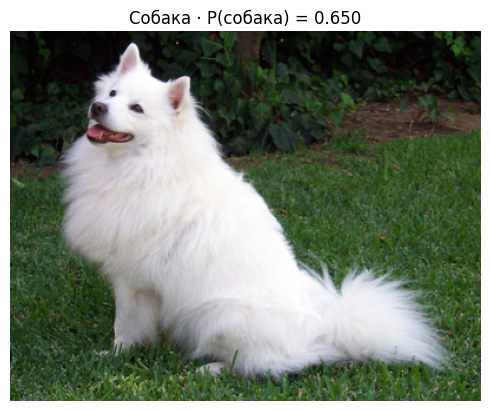

In [16]:
PHOTO_PATH = ""
photo = Path(PHOTO_PATH).expanduser() if PHOTO_PATH else hw4.demo_photo()
label, probability = classify_photo(photo, best_name)
show_photo(photo, probability)

## 3. Конкурсная часть на данных курса

В обязательной части задания нужно использовать предобученные VGG и ещё одну сеть. В конкурсной части действует другое правило: **любые готовые предобученные веса запрещены**. Поэтому веса ImageNet остаются только в разделе 2.

Начальные конкурсные сети обучаются со случайных весов. Сеть с увеличенным входом начинает с весов глубокой остаточной сети. Сеть с перекрытиями использует веса модели с обобщённым усреднением, а модель с вниманием — веса сети с перекрытиями. Дополнительные фотографии в этом варианте не используются.


### Данные для конкурсной части

Беру сохранённое разбиение с флагом `contest`, использованное при обучении ансамбля: 19 991 фото в обучающей выборке, 2 487 в проверочной и все 2 500 в тестовой. Оно отличается от флага `use` в обязательной части.

В таблице `train_audit_scores.csv` вместе с метками сохранены ответы ранних моделей. Они нужны для выбора трудных примеров и мягких целей при обучении модели с вниманием. Метки тестовой выборки в обучение не попадают.


In [17]:
import copy
import math
import os

from torch.nn import functional as F

import train_course as training
from contest import (
    Attention, DeepBasicBlock, MobileBottleneck, conv_norm,
    compact_inputs, augment, average,
)
from train_course import (
    course_parent, course_context_batches, course_amp,
    course_dev_mask, restore_course_context, course_scores,
    course_validation_key, save_course_epoch, save_course_progress,
)

course_device = contest.DEVICE
contest_rows = manifest.loc[manifest.contest]
course_train = pd.read_csv(manifests / "train_audit_scores.csv")
course_val = pd.read_csv(results / "validation.csv").sort_values("path")

contest_rows.groupby("split").size().reindex(
    ["train", "val", "test"]
).to_frame("Фотографии конкурсной части").rename(index={"train": "Обучающая выборка", "val": "Проверочная выборка", "test": "Тестовая выборка"}).rename_axis("Выборка")

,Фотографии конкурсной части
Выборка,
Обучающая выборка,19991
Проверочная выборка,2487
Тестовая выборка,2500


### Семь моделей ансамбля

В таблице указаны планы обучения. Для предсказания из каждого опыта взяты лучшие сохранённые веса по проверочной выборке, а не обязательно веса последней эпохи.

| Имя в коде | Архитектура и отличие | Начальные веса | Эпох | Шаг обучения в расписании | Размеры входа |
|---|---|---|---:|---|---|
| `deep_resnet` | Глубокая остаточная свёрточная сеть, блоки 3–4–6–3 | Случайные | 84 | 0,00125 | 112 → 160 → 224 |
| `mbconv` | Сеть с поканальными свёртками, блоки MBConv | Случайные | 64 | 0,0018 | 112 → 160 → 224 |
| `highres` | Глубокая остаточная сеть с увеличенным входом | Глубокая остаточная сеть | 18 | 0,00024 | 224 → 256 |
| `context_resnet` | Остаточная сеть с сохранением пропорций кадра | Случайные | 86 | 0,00135 | 112 → 160 → 224 |
| `label_control` | Остаточная сеть с обычным и обобщённым усреднением, исходная разметка | Случайные | 92 | 0,0013 | 112 → 160 → 224 → 256 |
| `masked` | Сеть с искусственными перекрытиями и двумя видами усреднения | Сеть с обобщённым усреднением | 12 | 0,00012 | 320 |
| `course_context` | Остаточная основа и два блока внимания | Сеть с перекрытиями | 22 | 0,00019; новые слои ×3,8 | 192 → 256 → 320 |

Сети определены ниже. Остаточные блоки, блоки с поканальными свёртками, блок внимания и операции над изображениями импортирую из `contest.py`.


In [18]:
class DeepResidualNet(nn.Module):

    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(
            conv_norm(3, 24, 3, 2),
            conv_norm(24, 24),
            conv_norm(24, 40),
            nn.MaxPool2d(3, 2, 1),
        )
        layers = []
        cin = 40
        for i, (width, count) in enumerate([(40, 3), (80, 4), (160, 6), (320, 3)]):
            for j in range(count):
                layers.append(DeepBasicBlock(cin, width, 2 if i and j == 0 else 1))
                cin = width
        self.stages = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(320, 1))

    def forward(self, x):
        return self.head(self.stages(self.stem(x)).mean((2, 3))).flatten()


class GeMResNet(DeepResidualNet):
    """Остаточная сеть с обычным и обобщённым усреднением."""

    def __init__(self):
        super().__init__()
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(640, 1))

    def forward(self, x):
        features = self.stages(self.stem(x)).float()
        mean = features.mean((2, 3))
        gem = features.clamp_min(1e-05).pow(3).mean((2, 3)).pow(1 / 3)
        return self.head(torch.cat((mean, gem), 1)).flatten()

В остаточном блоке две свёртки 3 × 3 и обходное соединение. В сети с двумя видами усреднения к обычному среднему добавляется обобщённое среднее с показателем 3: оно сильнее выделяет крупные активации.

Блок с поканальными свёртками сначала расширяет число каналов, применяет поканальную свёртку и внимание к каналам, затем сжимает их. В списке этапов `MOBILE_STAGES` перечислены ширина, расширение, шаг, ядро и число повторений.


In [19]:
MOBILE_STAGES = [
    (24, 1, 1, 3, 1),
    (32, 4, 2, 3, 2),
    (48, 4, 2, 5, 2),
    (80, 4, 2, 3, 3),
    (112, 4, 1, 5, 2),
    (176, 6, 2, 5, 3),
    (256, 6, 1, 3, 1),
]


class MobileContestNet(nn.Module):

    def __init__(self):
        super().__init__()
        blocks = [nn.Conv2d(3, 32, 3, 2, 1, bias=False), nn.BatchNorm2d(32), nn.SiLU()]
        cin = 32
        for width, factor, stride, kernel, repeats in MOBILE_STAGES:
            for i in range(repeats):
                blocks.append(
                    MobileBottleneck(
                        cin, width, factor, stride if i == 0 else 1, kernel
                    )
                )
                cin = width
        blocks.extend(
            [nn.Conv2d(cin, 640, 1, bias=False), nn.BatchNorm2d(640), nn.SiLU()]
        )
        self.features = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(640, 1))

    def forward(self, x):
        return self.head(self.features(x).mean((2, 3))).flatten()

Модель с вниманием берёт локальные и общие карты остаточной сети с обобщённым усреднением, переводит их в токены по 128 признаков и обрабатывает двумя блоками внимания с четырьмя головами. Первый токен даёт ответ классификатора. Дополнительный вектор из 64 признаков используется в функции потерь при обучении.


In [20]:
def context_features(self, x):
    local = self.base.stages[:13](self.base.stem(x))
    global_map = self.base.stages[13:](local)
    small = self.global_tokens(global_map)
    big = self.local(local)

    def tokens(z):
        return (z + self.pos(z)).flatten(2).transpose(1, 2)

    stack = torch.cat(
        [self.cls.expand(len(x), -1, -1), tokens(big), tokens(small)], dim=1
    )
    return self.blocks(stack)[:, 0]


def context_forward(self, x, embedding=False):
    summary = self.features(x)
    logits = self.classify(summary).flatten()
    if embedding:
        return (logits, F.normalize(self.project(summary).float(), dim=1))
    return logits


class Context(nn.Module):

    def __init__(self):
        super().__init__()
        self.base = GeMResNet()
        self.local = nn.Conv2d(160, 128, 1)
        self.global_tokens = nn.Conv2d(320, 128, 1)
        self.pos = nn.Conv2d(128, 128, 3, padding=1, groups=128)
        self.cls = nn.Parameter(torch.randn(1, 1, 128) * 0.02)
        self.blocks = nn.Sequential(Attention(128), Attention(128), nn.LayerNorm(128))
        self.classify = nn.Linear(128, 1)
        self.project = nn.Linear(128, 64)

    features = context_features
    forward = context_forward

### Обучение модели с вниманием

Мягкая цель — 96% исходной метки и 4% среднего ответа трёх ранних сетей. К бинарной кросс-энтропии добавляется потеря, сближающая векторы снимков одного класса.

После каждого шага обновляется сглаженная копия весов. Размер входа меняется с 192 на 256 и затем на 320; шаг алгоритма AdamW постепенно уменьшается.


In [21]:
def course_teacher(tr):
    teacher = tr[["deep_resnet", "mbconv", "context_resnet"]].mean(axis=1).to_numpy()
    y = tr.label.to_numpy()
    hardness = np.where(y, 1 - teacher, teacher)
    hard = np.flatnonzero(
        (hardness >= np.quantile(hardness, 0.80)) & (hardness <= 0.86)
    )
    return 0.96 * y + 0.04 * teacher, hard


def course_context_loss(logits, z, y):
    ce = F.binary_cross_entropy_with_logits(logits.float(), 0.992 * y + 0.004)
    similarity = (z @ z.T).float() / 0.14
    same_image = torch.eye(len(z), device=z.device, dtype=torch.bool)
    log_p = similarity.masked_fill(same_image, -1e4).log_softmax(dim=1)
    positive = ((y > 0.5)[:, None] == (y > 0.5)[None, :]) & ~same_image
    metric = -(log_p * positive).sum(1) / positive.sum(1).clamp_min(1)
    return ce + 0.09 * metric.mean(), ce


def course_optimizer_step(net, optimizer, loss, clip):
    loss.backward()
    nn.utils.clip_grad_norm_(net.parameters(), clip)
    optimizer.step()

In [22]:
def init_course_context(package, device):
    torch.manual_seed(86017)
    net = Context()
    parent = course_parent(net.base, package / "previous/masked_best.pt")
    net.base.head = nn.Identity()
    net.to(device, memory_format=torch.channels_last)
    ema = copy.deepcopy(net).requires_grad_(False).eval()
    heads = [p for name, p in net.named_parameters() if not name.startswith("base.")]
    opt = torch.optim.AdamW(
        [{"params": net.base.parameters()}, {"params": heads}],
        lr=0.0001,
        weight_decay=0.04,
        fused=device.type == "cuda",
    )
    return net, ema, opt, parent


def course_context_epoch(net, ema, opt, frames, target, hard, e, device):
    seed = 86017 + e
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)
    edge = 192 if e < 6 else 256 if e < 16 else 320
    batch = 28 if edge < 320 else 20
    lr = 0.00019 * (0.08 + 0.92 * (1 + math.cos(math.pi * e / 21)) / 2)
    opt.param_groups[0]["lr"] = lr * min(1, (e + 1) / 4)
    opt.param_groups[1]["lr"] = 3.8 * lr
    net.train()
    losses = []
    for ids in course_context_batches(len(frames), hard, batch, rng):
        x = compact_inputs(torch.from_numpy(frames[ids]), device, edge)
        x = augment(x, True)
        y = torch.as_tensor(target[ids], device=device, dtype=torch.float32)
        opt.zero_grad(set_to_none=True)
        with course_amp(device):
            logits, embeddings = net(x, embedding=True)
            loss, ce = course_context_loss(logits, embeddings, y)
        course_optimizer_step(net, opt, loss, 3.0)
        average(ema, net, 0.982)
        losses.append(ce.detach())
    return edge, float(torch.stack(losses).mean())

Для выбора эпохи смешиваются 65% предыдущего ансамбля и 35% новой модели. Сначала сравнивается число правильных ответов на 1 941 снимке проверочной части для подбора, затем логарифмические потери. После выбора эпохи вес модели в окончательном ансамбле подбирался отдельно и составил 20%.

Оставшиеся 546 снимков использовались для дополнительной проверки. Ранние модели настраивались по всей проверочной выборке, поэтому эта часть не является независимой тестовой выборкой.


In [23]:
def train_course_context(frames, valid, tr, val, package, folder, device):
    net, ema, opt, parent = init_course_context(package, device)
    target, hard = course_teacher(tr)
    dev = course_dev_mask(val.path)
    resume = folder / "course_context_resume.pt"
    rows, best = restore_course_context(resume, net, ema, opt, parent)
    for e in range(len(rows), 22):
        edge, loss = course_context_epoch(
            net, ema, opt, frames, target, hard, e, device
        )
        p = course_scores(
            ema, valid, edge, device, batch=28, amp=True, average_logits=True
        )
        combined = 0.65 * val.course.to_numpy() + 0.35 * p
        key = course_validation_key(val.label.to_numpy()[dev], combined[dev], eps=1e-7)
        if key > best:
            best = key
            state = dict(
                weights=ema.state_dict(), edge=edge, epoch=e + 1, parent=parent
            )
            save_course_epoch(folder, "course_context", state, val, p)
        rows.append(
            dict(epoch=e + 1, edge=edge, hits=key[0], dev_loss=-key[1], train_loss=loss)
        )
        save_course_progress(resume, net, ema, opt, parent, rows, best)
        pd.DataFrame(rows).to_csv(folder / "course_context_history.csv", index=False)
        print(
            f"Модель с вниманием, эпоха {e + 1:2d}: {key[0]}/{dev.sum()}, потери {-key[1]:.5f}"
        )
    return pd.DataFrame(rows)

Параметр `TRAIN_CONTEST` включает повторное обучение. По умолчанию оно выключено. Для модели с вниманием используются функции выше; остальные имена из таблицы запускают соответствующий этап существующего скрипта.

Это отдельные повторные опыты с сохранёнными весами предыдущих моделей. Они не пересобирают автоматически всю опубликованную цепочку. Новые веса записываются отдельно; дальнейшие таблицы показывают сохранённый итоговый ансамбль.


In [24]:
TRAIN_CONTEST = False
CONTEST_STAGES = ("course_context",)


def repeat_contest_training(stages):
    for name in stages:
        if name != "course_context":
            training.main(["--models", name])
            continue
        package = hw4.open_models("winners")
        folder = hw4.CACHE / "course-contest-training"
        folder.mkdir(parents=True, exist_ok=True)
        train_root = hw4.extract_photos(split="train")
        val_root = hw4.extract_photos(split="val")
        frames = training.pack_course_images(
            train_root, course_train.relative_path, 320, True, folder
        )
        valid = training.pack_course_images(
            val_root, course_val.path, 320, True, folder
        )
        run = train_course_context(
            frames, valid, course_train, course_val,
            package, folder, course_device,
        )
        print(run.tail(3).rename(columns={
            "epoch": "Эпоха", "edge": "Сторона изображения", "hits": "Верно",
            "dev_loss": "Проверочные потери", "train_loss": "Потери при обучении",
        }).to_string(index=False))


if TRAIN_CONTEST:
    repeat_contest_training(CONTEST_STAGES)

Сохранённый журнал обучения модели с вниманием:


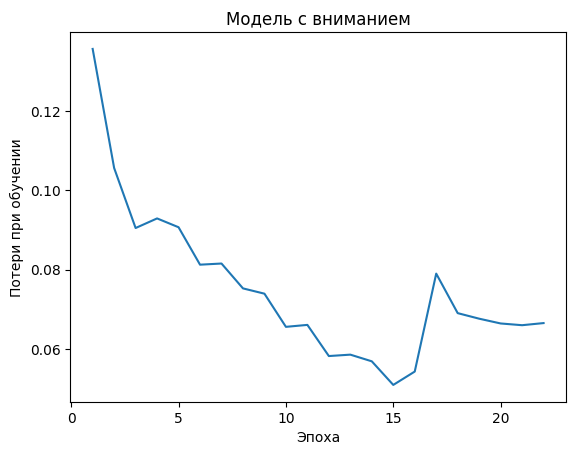

In [25]:
run = pd.read_csv(results / "course_context_history.csv")
ax = run.plot(x="epoch", y="train_loss", legend=False)
ax.set(xlabel="Эпоха", ylabel="Потери при обучении", title="Модель с вниманием")
plt.show()

### Загрузка семи обученных моделей

В словаре сопоставлены имена моделей, файлы весов и классы, определённые выше. Размер входа берётся из файла сохранённых весов. Параметры вариантов кадра и смешивания читаются из сохранённых настроек.


In [26]:
course_package = hw4.open_models("winners")
course_prior_dir = course_package / "previous/baseline/prior"
round2_config = contest.load_json(course_prior_dir / "round2/selection.json")
round3_config = contest.load_json(course_prior_dir / "round3/selection.json")
round4_config = contest.load_json(course_prior_dir / "round4/selection.json")
previous_config = contest.load_json(course_package / "previous/selection.json")
family_config = contest.load_json(course_package / "course_family_lock.json")

course_model_files = {
    "deep_resnet": course_prior_dir / "round2/deep_resnet_best.pt",
    "highres": course_prior_dir / "round2/highres_best.pt",
    "mbconv": course_prior_dir / "round2/mbconv_best.pt",
    "context_resnet": course_prior_dir / "round3/context_resnet_best.pt",
    "label_control": course_prior_dir / "round4/label_control_best.pt",
    "masked": course_package / "previous/masked_best.pt",
    "course_context": course_package / "course_context.pt",
}
course_factories = {
    "deep_resnet": DeepResidualNet,
    "highres": DeepResidualNet,
    "mbconv": MobileContestNet,
    "context_resnet": DeepResidualNet,
    "label_control": GeMResNet,
    "masked": GeMResNet,
    "course_context": Context,
}


def load_course_model(name):
    checkpoint = torch.load(
        course_model_files[name], map_location="cpu", weights_only=True
    )
    model = course_factories[name]()
    if name == "course_context":
        model.base.head = nn.Identity()
    field = "weights" if name == "course_context" else "state_dict"
    size = checkpoint["edge"] if name == "course_context" else checkpoint["size"]
    model.load_state_dict(checkpoint[field])
    model.eval().to(course_device, memory_format=torch.channels_last)
    return model, size

### Ответы по вариантам кадра

Ранние сети видят полный кадр, центральный и угловые вырезы, а также увеличенный вход. Для сети с сохранением пропорций и сети с обобщённым усреднением используются три способа подготовки: сохранение пропорций с полями, центральный квадрат и растяжение. У сети с перекрытиями и модели с вниманием остаётся кадр с сохранёнными пропорциями и полями.

Каждый вариант дополнительно отражается по горизонтали. Для первых шести моделей усредняются вероятности; у модели с вниманием сначала усредняются логиты, затем применяется сигмоида. Эта разница сохранена в коде предсказания.


In [27]:
@torch.inference_mode()
def round2_probability(name, paths):
    model, size = load_course_model(name)
    edge = 256 if name == "highres" else 224
    views = round2_config["members"][name]
    images = contest.resized_photos(".", paths, edge)
    parts = {}
    for view in sorted(set(views)):
        if view == "aspect":
            square = contest.aspect_crops(".", paths, edge)
            probability = contest.compact_scores(model, square, course_device, size)
        elif view in contest.CORNERS:
            side = round(0.82 * edge)
            y = edge - side if view.startswith("bottom") else 0
            x = edge - side if view.endswith("right") else 0
            crop = images[:, y:y + side, x:x + side, :]
            probability = contest.compact_scores(model, crop, course_device, size)
        else:
            probability = contest.contest_view(
                model, images, course_device, size, view
            )
        parts[view] = probability
    return np.mean([parts[view] for view in views], axis=0)

In [28]:
@torch.inference_mode()
def context_probability(name, paths, views, edge):
    model, size = load_course_model(name)
    views = [tuple(view) for view in views]
    parts = {}
    for geometry in sorted({view[0] for view in views}):
        images = contest.context_photos(".", paths, edge=edge, geometry=geometry)
        for view in views:
            if view[0] == geometry:
                parts[view] = contest.context_scores(
                    model, images, course_device, size, view[1]
                )
    return np.mean([parts[view] for view in views], axis=0)


def course_frames(paths, edge):
    frames = []
    for path in paths:
        with Image.open(path) as image:
            rgb = ImageOps.exif_transpose(image).convert("RGB")
            frames.append(contest.boxed_rgb(rgb, edge)[0])
    return np.stack(frames)

In [29]:
@torch.inference_mode()
def course_component_probabilities(paths):
    parts = {
        name: round2_probability(name, paths)
        for name in round2_config["members"]
    }
    views3 = next(
        member["views"] for member in round3_config["members"]
        if member["model"] == "context_resnet"
    )
    views4 = next(
        member["views"] for member in round4_config["members"]
        if member["model"] == "label_control"
    )
    parts["context_resnet"] = context_probability(
        "context_resnet", paths, views3, 224
    )
    parts["label_control"] = context_probability(
        "label_control", paths, views4, 256
    )
    model, size = load_course_model("masked")
    parts["masked"] = contest.masked_predict(
        model, course_frames(paths, size), size
    )
    model, size = load_course_model("course_context")
    parts["course_context"] = contest.predict_component(
        model, course_frames(paths, 320), size
    )
    return parts

### Как получается итоговая вероятность

Пусть \(L(p)=\log \frac{p}{1-p}\), а \(\sigma\) — сигмоида. Сначала каждая модель усредняет ответы по своим вариантам кадра. Затем используются сохранённые коэффициенты:

\[
\begin{aligned}
q_2 &= \sigma\left(\frac{L(p_{\text{глубокая}})+L(p_{\text{крупный вход}})+L(p_{\text{поканальная}})}{3}\right),\\
q_3 &= \sigma\left(0{,}5L(q_2)+0{,}5L(p_{\text{пропорции}})\right),\\
q_4 &= 0{,}65q_3+0{,}35p_{\text{усреднение}},\\
q_5 &= \sigma\left(0{,}55L(q_4)+0{,}45L(p_{\text{перекрытия}})\right),\\
p_{\text{итог}} &= 0{,}8q_5+0{,}2p_{\text{внимание}}.
\end{aligned}
\]

Собакой считается снимок с итоговой вероятностью не меньше 0,5.

In [30]:
def mean_log_odds(probabilities, weights=None):
    p = np.clip(np.asarray(probabilities, dtype=np.float64), 1e-6, 1 - 1e-6)
    logits = np.log(p) - np.log1p(-p)
    return 1 / (1 + np.exp(-np.average(logits, weights=weights, axis=0)))


def pair_log_odds(left, right, weight):
    left = np.clip(left, 1e-6, 1 - 1e-6)
    right = np.clip(right, 1e-6, 1 - 1e-6)
    combined = (
        (1 - weight) * np.log(left / (1 - left))
        + weight * np.log(right / (1 - right))
    )
    return 1 / (1 + np.exp(-combined))


def final_course_probability(previous, attention):
    weight = family_config["weight"]
    return (1 - weight) * previous + weight * attention


def combine_course_components(parts):
    q2 = mean_log_odds([
        parts[name] for name in round2_config["members"]
    ])
    q3 = mean_log_odds(
        [q2, parts["context_resnet"]], round3_config["weights"]
    )
    q4 = np.average(
        [q3, parts["label_control"]], weights=round4_config["weights"], axis=0
    )
    weight = previous_config["course"]["recipe"][1]
    q5 = pair_log_odds(q4, parts["masked"], weight)
    return final_course_probability(q5, parts["course_context"])

### Проверка ансамбля

Сначала показаны сохранённые проверки этапов при подборе ансамбля. Все они относятся к тем же 2 487 снимкам проверочной выборки, а не к независимой тестовой выборке.

Затем итоговая смесь заново считается по сохранённым ответам на части для подбора и дополнительной проверки. Столбец `course` содержит предыдущий ансамбль q₅; для него и модели с вниманием используется та же функция, что и для новых фотографий.


In [31]:
stage_checks = [
    ("Три исходные сети", round2_config["val_correct"], round2_config["val_n"]),
    ("+ сеть с сохранением пропорций", round3_config["correct"], round3_config["n"]),
    ("+ сеть с обобщённым усреднением", round4_config["correct"], round4_config["n"]),
    ("+ сеть с перекрытиями", previous_config["course"]["correct"], previous_config["n"]),
    ("+ модель с вниманием", family_config["validation"]["all"]["after"]["correct"],
     family_config["validation"]["all"]["after"]["n"]),
]
stages = pd.DataFrame(stage_checks, columns=["Этап", "Верно", "Всего"])
stages["Accuracy"] = stages["Верно"] / stages["Всего"]
display(stages.set_index("Этап").rename(columns={"Accuracy": "Доля верных ответов"}))

dev = course_dev_mask(course_val.path)
validation_scores = {}
for split, mask in [
    ("validation-dev", dev),
    ("validation-check", ~dev),
    ("Вся validation", np.ones(len(course_val), dtype=bool)),
]:
    rows = course_val.loc[mask]
    validation_scores[split] = accuracy(
        rows.label, final_course_probability(rows.course, rows.course_context)
    )
pd.DataFrame(validation_scores).T.rename(
    index={
        "validation-dev": "Часть для подбора",
        "validation-check": "Часть дополнительной проверки",
        "Вся validation": "Вся проверочная выборка",
    },
    columns={"Accuracy, %": "Точность, %"},
).rename_axis("Выборка")


,Верно,Всего,Доля верных ответов
Этап,,,
Три исходные сети,2453,2487,0.986329
+ сеть с сохранением пропорций,2454,2487,0.986731
+ сеть с обобщённым усреднением,2457,2487,0.987937
+ сеть с перекрытиями,2459,2487,0.988741
+ модель с вниманием,2460,2487,0.989144


,Верно,Всего,"Точность, %"
Выборка,,,
Часть для подбора,1919.0,1941.0,98.87
Часть дополнительной проверки,541.0,546.0,99.08
Вся проверочная выборка,2460.0,2487.0,98.91


### Итоговый тест и отдельная фотография

Функция `predict_course` принимает список путей к изображениям и возвращает итоговые вероятности собаки. Она загружает семь моделей, определённых выше, и применяет описанные варианты кадра и формулы. Обучение из этой функции не запускается.


In [32]:
@torch.inference_mode()
def predict_course(paths):
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    files = [str(Path(path).resolve()) for path in paths]
    chunks = []
    for start in range(0, len(files), 64):
        parts = course_component_probabilities(files[start:start + 64])
        chunks.append(combine_course_components(parts))
    return np.concatenate(chunks) if chunks else np.empty(0)

При `RUN_TEST = True` итог заново считается по всем 2 500 фотографиям тестовой выборки. При обычном запуске читаются сохранённые ответы того же ансамбля. Отдельная фотография ниже в любом случае проходит полный расчёт.


In [33]:
if RUN_TEST:
    root = hw4.extract_photos(split="test")
    rows = manifest.loc[manifest.split == "test"].sort_values("relative_path")
    paths = [root / path for path in rows.relative_path]
    probability = predict_course(paths)
    test = rows[["relative_path", "label"]].rename(
        columns={"relative_path": "path"}
    ).reset_index(drop=True)
    test["prob_dog"] = probability
else:
    test = pd.read_csv(results / "course_test.csv")
    probability = test.official
accuracy(test.label, probability).rename(index={"Accuracy, %": "Точность, %"}).to_frame("Конкурсная часть")

,Конкурсная часть
Верно,2464.00
Всего,2500.00
"Точность, %",98.56


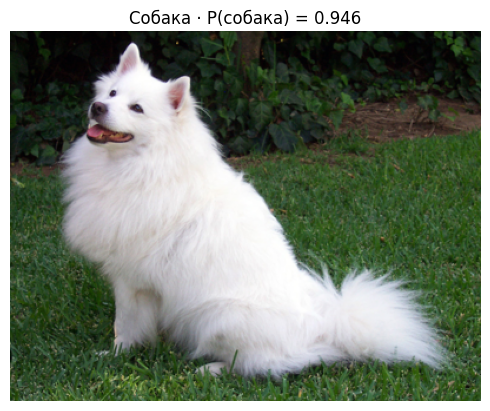

In [34]:
photo_probability = predict_course([photo])[0]
show_photo(photo, photo_probability)

## Выводы

Свёрточная сеть дала точность 78,48%, VGG16 — 98,36%, ResNet18 — 98,44%. В обязательной части перенос обучения заметно повысил точность.

Курсовой ансамбль из семи собственных моделей правильно распознал 2 464 из 2 500 снимков: 98,56%. Он соблюдает правило конкурсной части о запрете готовых предобученных весов, но требует больше вычислений, чем одна сеть.
